In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
import pandas as pd
from tqdm.notebook import tqdm
import ast
tqdm.pandas()
from socialvec.socialvec import SocialVec
import random

from utils import parse_friends_ids

2026-01-19 07:49:56.035609: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-19 07:49:57.539655: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-01-19 07:49:58.827876: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-01-19 07:49:58.827922: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-01-19 07:49:58.834372: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [87]:
all_topics = pd.read_excel("../data/popular_accounts_manually_validated.xlsx", sheet_name=None)
#df_users = pd.read_excel("../data/new_mean_average_percision.xlsx", sheet_name="SelectedUsers")
df_users = pd.read_pickle("../data/users_selected_for_the_experiment2.pkl")


In [88]:
#df_users = pd.read_csv("../data/users_selected_for_the_experiment.csv")

In [89]:
df_users['friends_count'] = df_users['friends_count'].astype(int)

In [90]:
# if you used the excel for the df_users, you need to parse the users:
#convert data from string to list
#df_users["friends_ids"] = df_users.apply(parse_friends_ids, axis=1)

In [91]:
df_users[df_users['friends_count']!=0]['friends_count'].describe().apply(lambda x: format(x, ',.02f'))

count    13,798.00
mean      1,754.86
std       1,428.83
min           1.00
25%         603.00
50%       1,289.00
75%       2,559.00
max       5,000.00
Name: friends_count, dtype: object

In [92]:
df_users = df_users[~df_users['account_selected_for'].isna()]

In [93]:
df_accounts = pd.DataFrame()

for i in all_topics:
    all_topics[i] = all_topics[i][all_topics[i]['use']==1].copy()
    df_accounts = pd.concat([df_accounts, all_topics[i]])

df_accounts = df_accounts[df_accounts['use']==1]
df_accounts['twitter_user_id'] = df_accounts['twitter_user_id'].astype(int)
df_accounts.drop(df_accounts.columns[df_accounts.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)

In [94]:
df_accounts['followers_count'].describe().apply(lambda x: format(x, ',.02f'))

count            276.00
mean       8,366,736.22
std       18,025,941.11
min           20,642.00
25%          510,939.00
50%        1,873,836.00
75%        6,500,807.50
max      115,819,215.00
Name: followers_count, dtype: object

In [97]:
account_list = df_accounts['twitter_user_id'].values
topic_list = [t for t in all_topics]

In [98]:
#keep only users with the relevant topics (since we removed some)
print(df_users.shape[0])
df_users = df_users[df_users['topic'].isin(topic_list)]
print(df_users.shape[0])

13800
13800


In [99]:
def get_relevant_subset_users(x):
    return list(set(x).intersection(set(account_list)))

In [100]:
df_users["number_of_accounts_full_sv"] = df_users["friends_ids"].apply(lambda x: len(x))
df_users["experiment_accounts"] = df_users["friends_ids"].apply(get_relevant_subset_users)
df_users["number_of_accounts_from_experiment"] = df_users["experiment_accounts"].apply(lambda x: len(x))

In [101]:
df_users["number_of_accounts_from_experiment"].describe().apply(lambda x: format(x, ',.02f'))

count    13,800.00
mean         33.74
std          25.69
min           1.00
25%          13.00
50%          27.00
75%          49.00
max         170.00
Name: number_of_accounts_from_experiment, dtype: object

In [102]:
minimal_number_of_accounts = 10

number_of_users_before_filtering = df_users.shape[0]
df_users = df_users[df_users["number_of_accounts_from_experiment"]>minimal_number_of_accounts]
print(f"removed {number_of_users_before_filtering - df_users.shape[0]} users in order to use only users who follow more than {minimal_number_of_accounts} users")
print(f"Using {df_users.shape[0]/number_of_users_before_filtering:.0%} of the users")

removed 2647 users in order to use only users who follow more than 10 users
Using 81% of the users


In [103]:
def find_number_of_categories_per_user(list_of_accounts):
    num_of_categories = 0
    for t in all_topics:
        all_topics[t]['twitter_user_id'] = all_topics[t]['twitter_user_id'].astype(int)
        if len (set(all_topics[t]['twitter_user_id'].values).intersection(set(list_of_accounts))) > 0:
            num_of_categories += 1
    return num_of_categories

In [104]:
df_users['number_of_categories_this_user_follows'] = df_users["experiment_accounts"].progress_apply(find_number_of_categories_per_user)

  0%|          | 0/11153 [00:00<?, ?it/s]

In [105]:
sv = SocialVec()

✅  Initializing Model
✅  Load Metadata


In [106]:
df_users["experiment_accounts_str"] = df_users["experiment_accounts"].progress_apply(lambda x: [str(i) for i in x])

  0%|          | 0/11153 [00:00<?, ?it/s]

### 16. Separation Logic
Define function to split friends into **Topic Accounts** (ground truth) and **Non-Topic Accounts** (context for embedding)

In [107]:
def seperate_topic_accounts(user_account_list, topic_account_list):
    user_accounts = set(user_account_list)
    topic_accounts = set(topic_account_list)
    return list(user_accounts - topic_accounts), list(user_accounts.intersection(topic_accounts))

In [108]:
from scipy.spatial.distance import cosine
import numpy as np
from typing import List, Tuple, Dict

def get_sv_rank(
    user_vec: np.ndarray,
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    """
    Build a DataFrame of cosine similarities between one user vector and
    all relevant account vectors.
    """
    records = []
    for i, row in relevant_vecs.iterrows():
        records.append({
            'account': row['twitter_screen_name'],
            'twitter_user_id':row['twitter_user_id'],
            'similarity': cosine(row['account_sv'], user_vec)
        })
    sv_ranked_list = pd.DataFrame(records).sort_values(by='similarity', ascending=True).reset_index(drop=True).reset_index()
    sv_ranked_list.rename(columns={'index':'rank'}, inplace=True)
    sv_ranked_list['rank'] = sv_ranked_list['rank'] + 1
    return sv_ranked_list

def get_popular_rank(
        relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    popularity_rank = relevant_vecs.sort_values(by=['followers_count'], ascending=False).reset_index(drop=True).reset_index()
    popularity_rank.rename(columns={'index':'rank',
                                    'twitter_screen_name':'account'}, inplace=True)
    popularity_rank['rank'] = popularity_rank['rank'] + 1
    return popularity_rank[['rank','account','twitter_user_id']]

### 17. Ranking Functions
Define `get_sv_rank` (Cosine Similarity) and `get_popular_rank` (Follower Count) to rank accounts.

### 18. Metric: Mean Average Precision (MAP)

### 19. Rank Normalization
Helper to filter a full ranked list down to specific topic accounts and reset rank indices (1, 2, 3...)

In [109]:
def reset_and_rank_topic_accounts(df, topic_accounts):
    df = df[df['twitter_user_id'].isin(topic_accounts)]
    df = df.reset_index(drop=True)
    df = df.reset_index()
    df['index'] = df['index'] + 1
    return df

### 20. Pre-calculate Embeddings
Compute SocialVec embeddings for all topic accounts once to optimize performance.

In [110]:
# Calculate Topics SV
for topic in topic_list:
    #all_topics[topic]['twitter_user_id'] = all_topics[topic]['twitter_user_id'].astype(int).astype(str)
    all_topics[topic]['account_sv'] = all_topics[topic]['twitter_user_id'].apply(lambda x: sv[x])

### 21. Topic Data Preparation
Define function to separate friends lists into context/target sets for a specific topic experiment.

In [113]:
def prepare_df_for_topic(topic, df_users):
    df_for_topic = df_users[df_users['topic'] == topic].copy()
    df_for_topic[["non_topic_accounts","topic_accounts"]] = df_for_topic['experiment_accounts'].apply( lambda x: pd.Series(seperate_topic_accounts(x,all_topics[topic]['twitter_user_id'].values)))
    # Just for visibility and debug, save the account names also
    #df_for_topic['topic_accounts_str'] = df_for_topic['topic_accounts'].apply(lambda x:[sv.get_screen_name(str(i) )for i in x])
    #df_for_topic['non_topic_accounts_str'] = df_for_topic['non_topic_accounts'].apply(lambda x:[sv.get_screen_name(str(i) )for i in x])
    return df_for_topic

In [114]:
def list_str(my_list):
    return [str(i) for i in my_list]

### 23. Pre-process All Topics
Loop through all topics and prepare the dataframes using the function defined above.",

In [115]:
df_for_all_topic = {}
for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    df_for_all_topic[topic] = prepare_df_for_topic(topic, df_users)

  0%|          | 0/14 [00:00<?, ?it/s]

### 23.5 temp statistics

In [ ]:
df_stats = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic].copy()
    
    df_for_topic['number_of_non_topic_accounts'] = df_for_topic['non_topic_accounts'].apply(lambda x: len(x))
    df_for_topic['number_of_topic_accounts'] = df_for_topic['topic_accounts'].apply(lambda x: len(x))
    df_for_topic['topic'] = topic
    
    df_stats = pd.concat([df_stats,df_for_topic])

In [ ]:
pd.options.display.float_format = "{:,.2f}".format

In [ ]:
df_stats[['topic','friends_ids_len',
              'number_of_accounts_from_experiment',
              'number_of_categories_this_user_follows',
              'number_of_non_topic_accounts',
              'number_of_topic_accounts' ]].describe().T


In [ ]:
del df_stats

## 24. Mean Average Precision (MAP) Calculations for the experiment 'small' world
Iterate through all topics and users. Calculate MAP scores for:

1. **Full SocialVec**: Using all non-topic friends.
2. **Sampled SocialVec**: Using random subsets (10-50 friends).
3. **Popularity**: Using follower counts.

In [ ]:
map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        user_experiment_account_except_selected_accounts = user['non_topic_accounts_str']
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50]:
            if sample_size < len(user['non_topic_accounts']):
                random.seed(76)
                acounts_for_sample = random.sample(user['non_topic_accounts'],sample_size)
            else:
                acounts_for_sample = user['non_topic_accounts']
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get SV rank when using only the accounts in the experiment (exculing the one of the selected topic)
        non_topic_accounts_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(user['non_topic_accounts']))[0],all_topics[topic])
        non_topic_accounts_sv_rank = reset_and_rank_topic_accounts(non_topic_accounts_sv_rank, user['topic_accounts'])
    
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


- **fullsv_map**: Mean Average Precision calculated on the full SV embeddings
- **experimantsv_map**: Mean Average Precision calculated based on SV embeddings that was calculated only on accounts from the experiment
- **exp_sv_sample__10_map** calculated based only on X (10) accounts **from the experiment**

In [132]:
pd.set_option('display.float_format', '{:,.3f}'.format)
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()
threshold_restuls

,topic,fullsv_map,experimantsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map
0,Actor,0.647,0.602,0.521,0.598,0.604,0.601,0.601,0.602
1,Comedian,0.599,0.594,0.545,0.584,0.590,0.593,0.594,0.594
2,Film,0.399,0.241,0.221,0.244,0.244,0.239,0.241,0.241
3,Journalist,0.675,0.640,0.622,0.640,0.640,0.640,0.640,0.640
4,MusicalArtist,0.633,0.591,0.520,0.584,0.589,0.591,0.591,0.592
5,Politician,0.777,0.755,0.720,0.754,0.756,0.755,0.755,0.755
6,Resturants,0.499,0.481,0.492,0.474,0.482,0.481,0.481,0.480
7,SportsTeam,0.510,0.385,0.349,0.381,0.386,0.385,0.385,0.386
8,TelevisionHost,0.428,0.394,0.301,0.389,0.390,0.394,0.393,0.394
9,TelevisionShow,0.635,0.551,0.365,0.532,0.549,0.551,0.549,0.550


In [50]:
df_users.groupby(by=['topic'])['number_of_accounts_full_sv'].describe()

,count,mean,std,min,25%,50%,75%,max
topic,,,,,,,,
Actor,809.000,"1,839.532","1,403.832",72.000,754.000,"1,325.000","2,665.000","4,999.000"
Comedian,854.000,"1,889.864","1,417.589",71.000,772.000,"1,433.500","2,629.000","4,999.000"
Film,741.000,"2,261.136","1,385.206",170.000,"1,136.000","1,946.000","3,186.000","4,999.000"
Journalist,948.000,"1,991.842","1,438.794",110.000,820.000,"1,573.500","2,886.250","4,999.000"
MusicalArtist,720.000,"1,677.001","1,385.077",82.000,597.750,"1,190.000","2,311.500","4,999.000"
Politician,804.000,"1,788.853","1,430.423",61.000,636.000,"1,300.500","2,627.250","4,999.000"
Resturants,803.000,"2,203.902","1,450.193",153.000,985.000,"1,874.000","3,200.500","4,999.000"
SportsTeam,691.000,"1,747.077","1,369.383",59.000,681.500,"1,330.000","2,445.500","4,999.000"
TelevisionHost,835.000,"2,255.048","1,458.516",110.000,"1,048.000","1,968.000","3,384.000","4,999.000"


In [ ]:
map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()

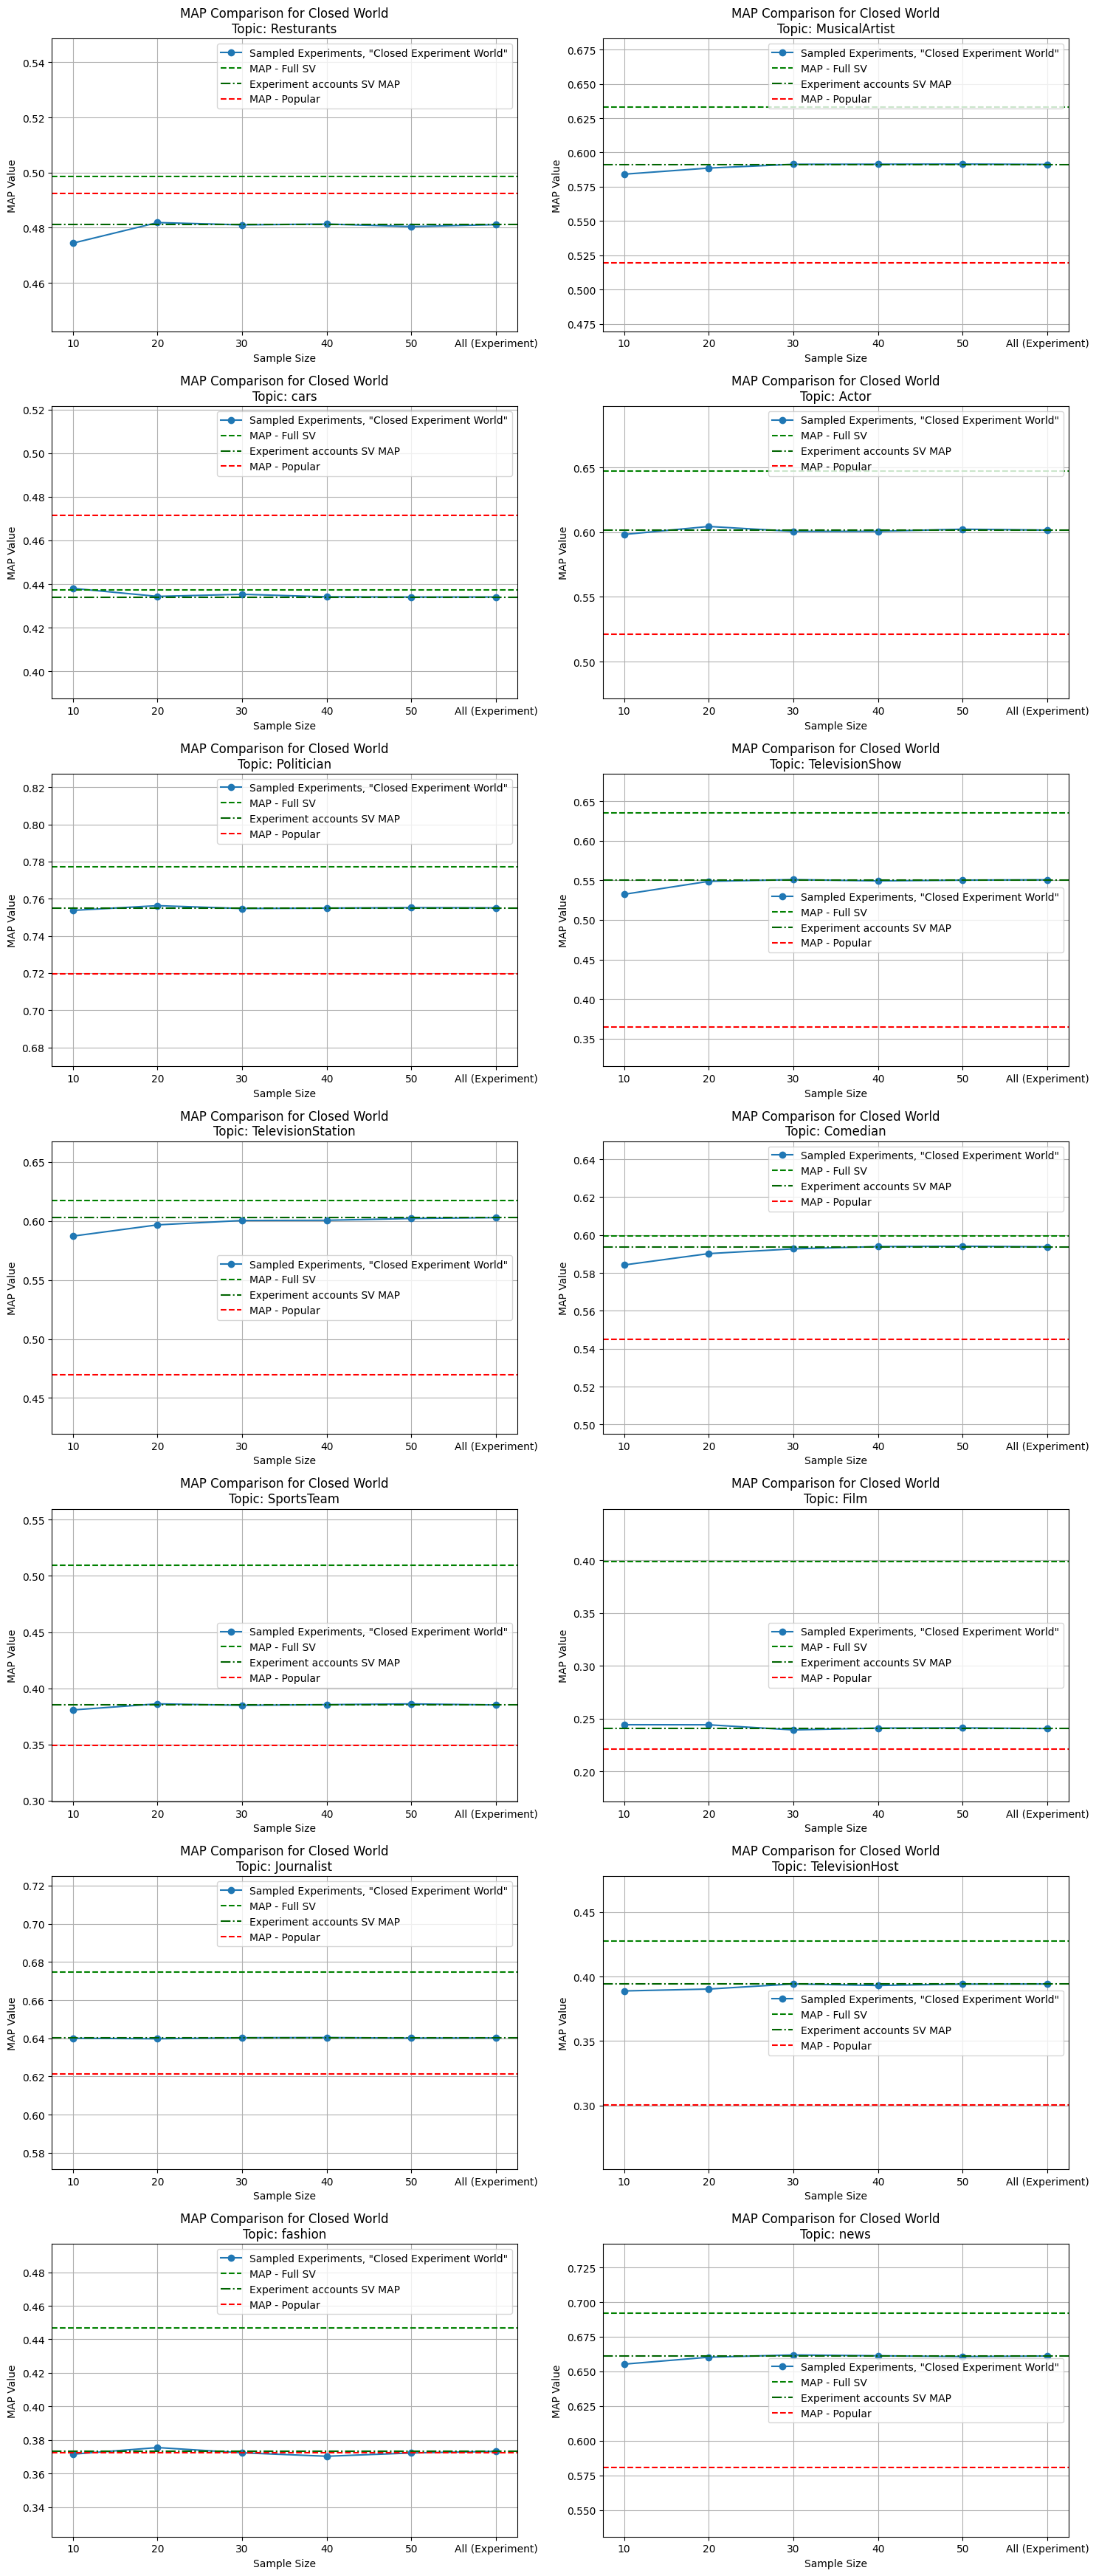

In [136]:
import matplotlib.pyplot as plt
import math

# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50','All (Experiment)']
    y_values = [
        row['exp_sv_sample__10_map'],
        row['exp_sv_sample__20_map'],
        row['exp_sv_sample__30_map'],
        row['exp_sv_sample__40_map'],
        row['exp_sv_sample__50_map'],
        row['experimantsv_map'],
    ]
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments, "Closed Experiment World"')

    # Calculate Y limits based on your logic
    max_y = max(row['fullsv_map'], row['popular_map']) + 0.05
    min_y = min(row['fullsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['fullsv_map'], color='green', linestyle='--', label='MAP - Full SV')
    ax.axhline(y=row['experimantsv_map'], color='darkgreen', linestyle='-.', label='Experiment accounts SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='MAP - Popular')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Closed World\nTopic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison.png', dpi=300)
plt.show()

# Mean Average Precision (MAP) on All Accounts
* here we don't evaluate only the accounts in the experiment, but we show a growing trend on all accounts (excluding the category),
meaning we don't limit our 'world' for a cold start scenario

In [ ]:
# להוסיף ניסויים בקפיצות 
10,20,30,40,50,80,100,
להוציא את כלהחשבונות של הקטגוריה של הקטגוריה מחוץ למדגם
וגם את המקסימום
פשוט לא להגביל רק לחשבונות שנשארים בניסוי

להוציא גם טבלה וגם גרפים עם התוצאות.

לבדוק קורלציה בין קטגוריות (שמישהו שעוקב אחרי ספורט עוקב גם אחרי)
============
tsne על 20 musical artists ביחד עם עוד שתי קטגוריות
לנסות להראות שהם מתקבצים לא בהכרח לפי הנושא
cluster של ישויות מכל מני סוגים

===============
משתמשים מהניסוי שעשינו ולעשות להם ניבוי תכונות לפי - המשתמשים מהקובץ הזה
פרופיל של מי שעוקב אחרי משתמשים מסויימים (גיל, השכלה, מין)

כמו במאמר של ענבר אולי המפה הזאת

אלאניס מוריסט מול מדונה
ציר x זה הקטגוריות, ציר ה-y זה אחוז מהקטגוריה (אחוז נשים למשל)

In [ ]:

map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50, 80, 100, 300, 500, 5000]:
            if sample_size < len(user_all_accounts_except_selected_accounts):
                random.seed(76)
                acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
            else:
                acounts_for_sample = user_all_accounts_except_selected_accounts
                
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
#                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
#                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


In [138]:
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()
threshold_restuls

,topic,fullsv_map,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map,exp_sv_sample__80_map,exp_sv_sample__100_map,exp_sv_sample__300_map,exp_sv_sample__500_map,exp_sv_sample__5000_map
0,Actor,0.647,0.521,0.609,0.623,0.632,0.635,0.637,0.641,0.642,0.648,0.649,0.647
1,Comedian,0.599,0.545,0.573,0.581,0.587,0.591,0.593,0.597,0.599,0.601,0.598,0.599
2,Film,0.399,0.221,0.341,0.356,0.368,0.375,0.372,0.393,0.398,0.397,0.401,0.399
3,Journalist,0.675,0.622,0.641,0.655,0.663,0.665,0.668,0.670,0.671,0.672,0.674,0.675
4,MusicalArtist,0.633,0.520,0.603,0.613,0.622,0.628,0.625,0.629,0.629,0.633,0.632,0.633
5,Politician,0.777,0.720,0.753,0.764,0.769,0.769,0.774,0.774,0.776,0.777,0.777,0.777
6,Resturants,0.499,0.492,0.470,0.485,0.482,0.485,0.485,0.490,0.490,0.496,0.496,0.499
7,SportsTeam,0.510,0.349,0.463,0.471,0.484,0.493,0.495,0.503,0.506,0.509,0.510,0.510
8,TelevisionHost,0.428,0.301,0.379,0.414,0.416,0.426,0.422,0.425,0.422,0.427,0.431,0.428
9,TelevisionShow,0.635,0.365,0.566,0.597,0.612,0.618,0.622,0.625,0.624,0.631,0.635,0.635


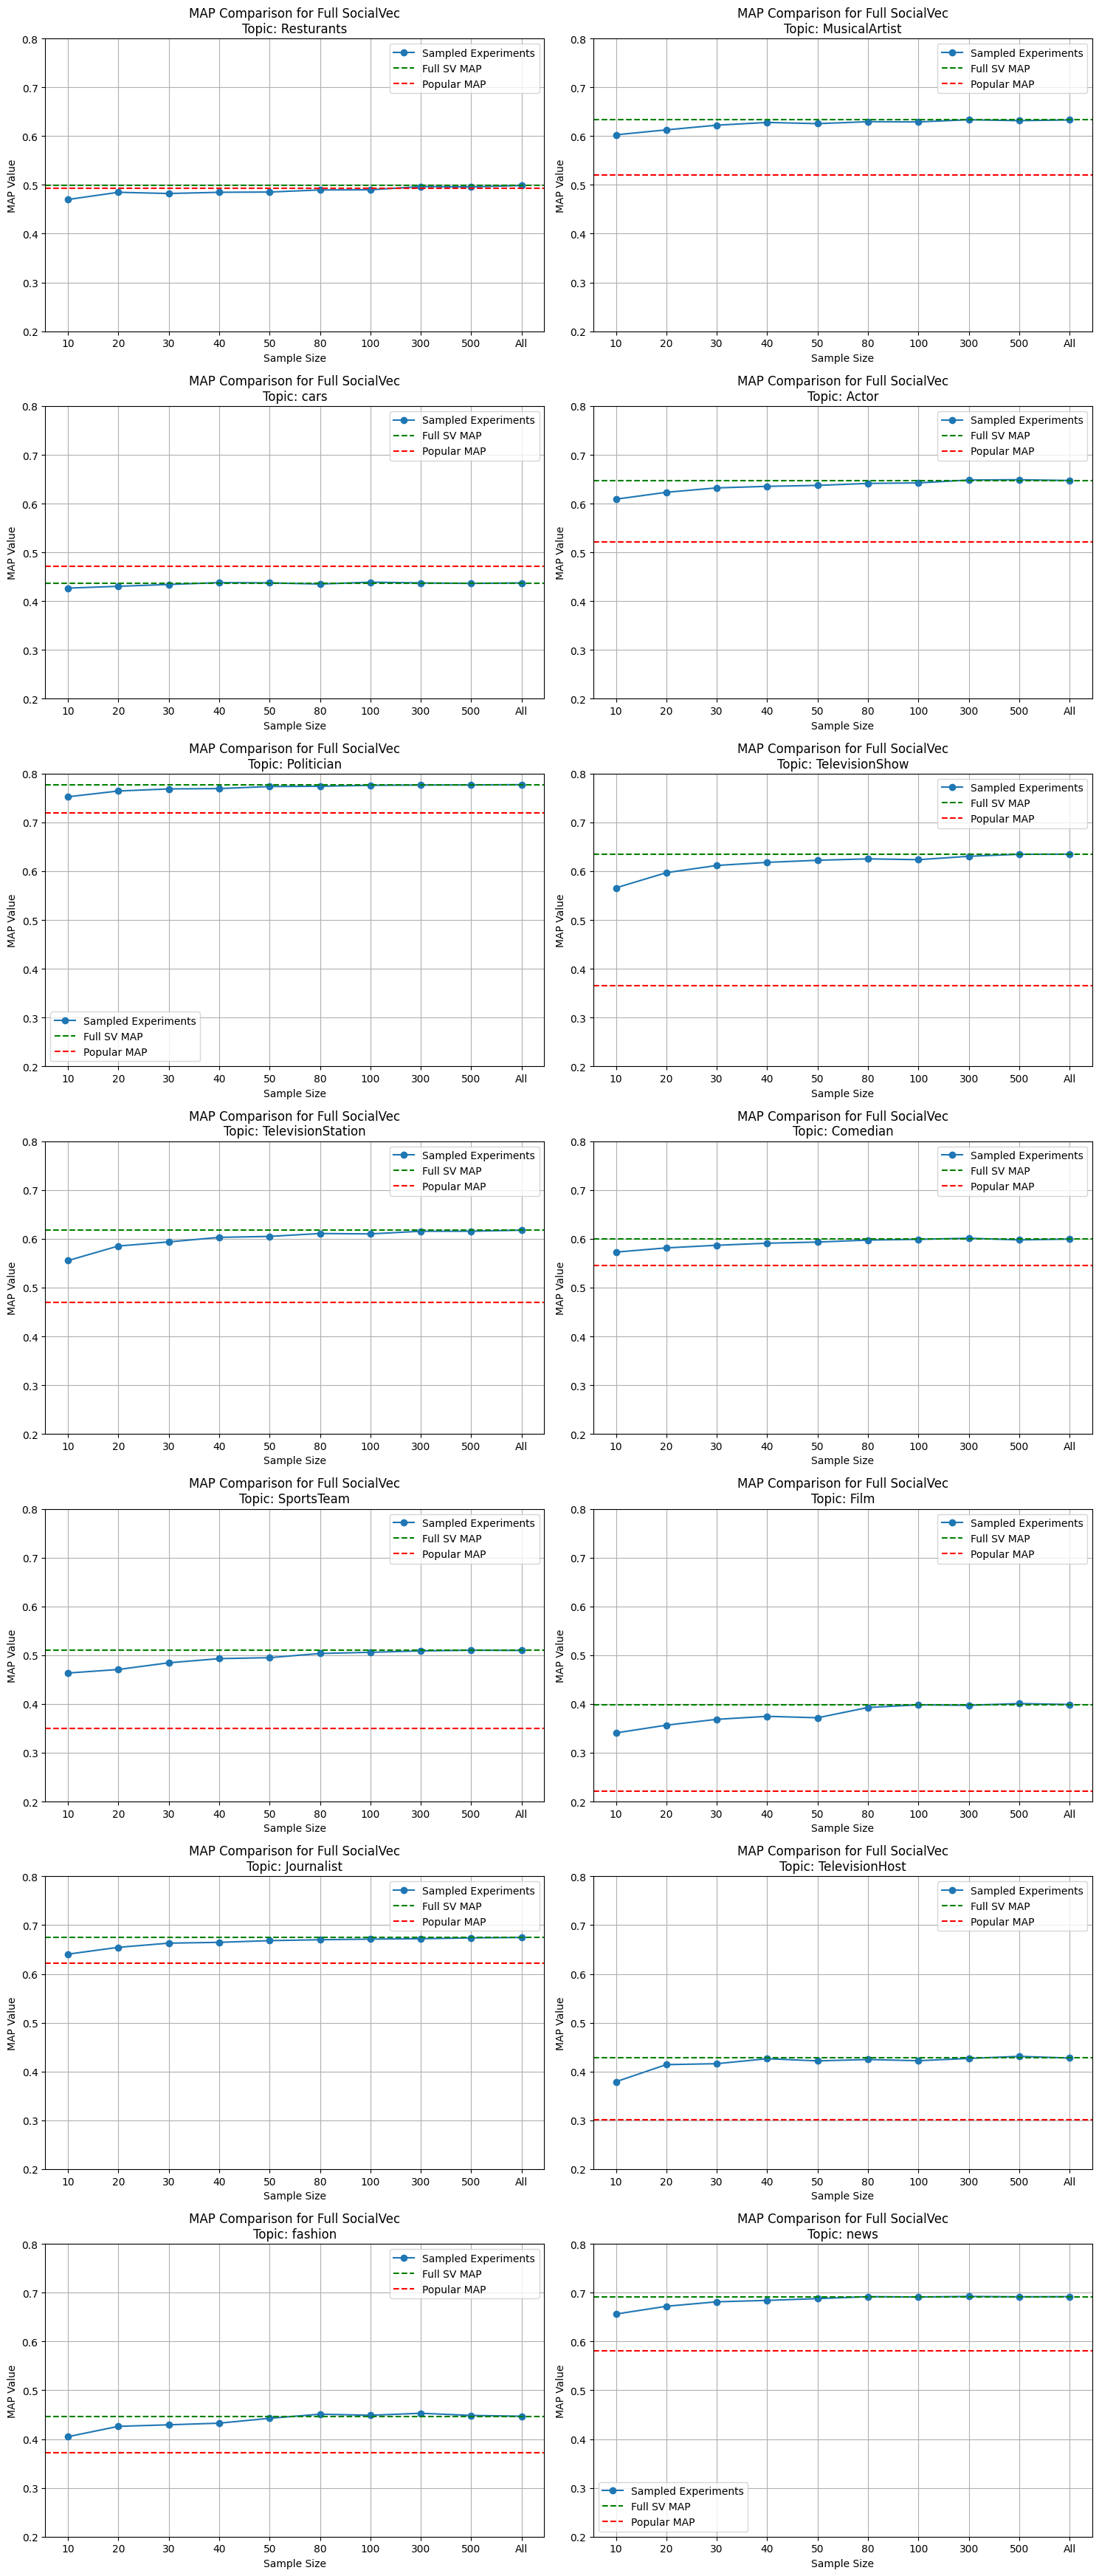

In [188]:
import matplotlib.pyplot as plt
import math

columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()


# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50', '80', '100', '300', '500', '5000']
    y_values = [row[f'exp_sv_sample__{value}_map'] for value in x_labels]
    x_labels[-1] = 'All'
    x_labels
    
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments')

    # Calculate Y limits based on your logic
    max_y = 0.8#= max(row['fullsv_map'], row['popular_map']) + 0.05
    min_y = 0.2#= min(row['fullsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['fullsv_map'], color='green', linestyle='--', label='Full SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='Popular MAP')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Full SocialVec\nTopic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison2.png', dpi=300)
plt.show()

# TSNE reflection

# Generate data for Tensorboard Embeddings Projector

In [34]:
import csv
import os
import numpy as np

# Define output paths
output_dir = 'outputs'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

vectors_path = os.path.join(output_dir, 'vectors.tsv')
metadata_path = os.path.join(output_dir, 'metadata.tsv')

with open(vectors_path, 'w', newline='', encoding='utf-8') as vec_file, \
     open(metadata_path, 'w', newline='', encoding='utf-8') as meta_file:
    
    vec_writer = csv.writer(vec_file, delimiter='\t')
    meta_writer = csv.writer(meta_file, delimiter='\t')
    
    # Write metadata header
    meta_writer.writerow(['Topic', 'Twitter Screen Name', 'Twitter Name'])
    
    count = 0
    for topic in all_topics:
        df = all_topics[topic]
        
        # Check if required columns exist
        if 'account_sv' not in df.columns:
            print(f"Skipping topic {topic}: 'account_sv' column missing")
            continue
            
        for _, row in df.iterrows():
            embedding = row['account_sv']
            
            # Ensure embedding is a valid numpy array of length 100
            if isinstance(embedding, np.ndarray) and len(embedding) == 100:
                # Write embedding vector
                vec_writer.writerow(embedding)
                
                # Get metadata fields
                screen_name = row.get('twitter_screen_name', '')
                # Try to find name, default to empty string if not found
                name = row.get('twitter_name', row.get('name', ''))
                
                # Write metadata
                meta_writer.writerow([topic, screen_name, name])
                count += 1

print(f"Successfully generated TensorBoard files with {count} embeddings.")
print(f"Vectors file: {vectors_path}")
print(f"Metadata file: {metadata_path}")

Successfully generated TensorBoard files with 276 embeddings.
Vectors file: outputs/vectors.tsv
Metadata file: outputs/metadata.tsv


# Attributes of the users in the experiment

In [171]:
def count_matches(row_list, comparison_set):
    return len(set(row_list).intersection(comparison_set))

In [189]:
current_topic = 'fashion'

account_list_int = [int(x) for x in df_for_all_topic[current_topic].head(20)['user_id'].values]

In [190]:
accounts_set = set(account_list_int)

df_users_with_attributes['match_count'] = df_users_with_attributes['friends_ids'].apply(lambda x: count_matches(x, accounts_set))

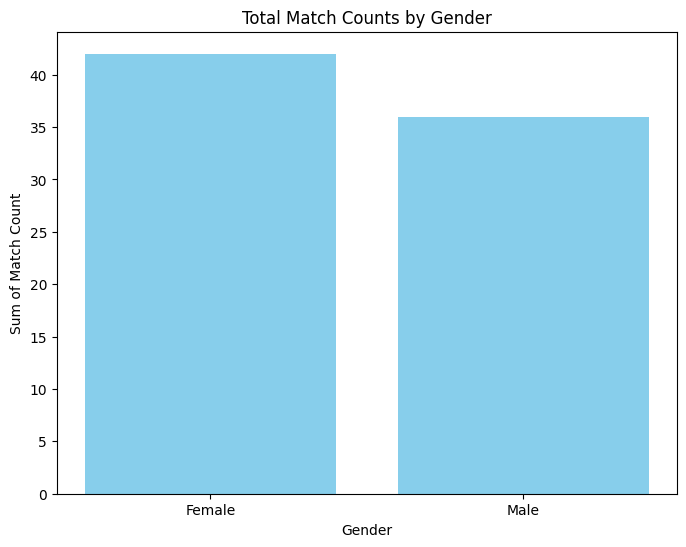

In [192]:
import pandas as pd
import matplotlib.pyplot as plt

# ... (Assuming df_users_with_attributes is already loaded) ...

# 1. Filter
clean_df = df_users_with_attributes.dropna(subset=['gender_prediction'])
clean_df = clean_df[clean_df['gender_label'] != 'Unknown']

# 2. Group
grouped_df = clean_df.groupby('gender_label')['match_count'].sum().reset_index()

# 3. Plot
plt.figure(figsize=(8, 6))

# We store the bar container to ensure x-axis alignment
bars = plt.bar(grouped_df['gender_label'], grouped_df['match_count'], color='skyblue')

# --- THE FIX ---
# Explicitly tell Matplotlib to use the gender names as labels for the x-axis positions
plt.xticks(
    ticks=range(len(grouped_df)),                # The positions (0, 1, 2...)
    labels=grouped_df['gender_label'],      # The names ('Male', 'Female'...)
    rotation=0                                   # Set to 45 if labels overlap
)
# ---------------

plt.xlabel('Gender')
plt.ylabel('Sum of Match Count')
plt.title('Total Match Counts by Gender')

plt.show()

# Classifier 2020c

In [35]:
sv_cls = SocialVec("2020c")

#init the classifier
sv_cls.init_classifier()

✅  Initializing Model
✅  Load Metadata


In [36]:
def check_classifier(single_user, expected_class, classifier_name):
    user = sv_cls.get_average_embeddings([sv_cls.get_userid(single_user)])[0]
    prediction = sv_cls.classifier.predict(classifier_name, user)
    if prediction[0] == expected_class:
        print(f"TEST PASSED. Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")
    else:
        print(f"FAILED! Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")


In [37]:
check_classifier("BarackObama", "Democrat", "political")
check_classifier("ChickfilA", "Republican", "political")
check_classifier("RapSheet", "Male", "gender")
check_classifier("ChelseaHouska", "Female", "gender")
check_classifier("RASHEEDA", "AfrAmerican", "ethnicity")
check_classifier("Country_Words", "Caucasian", "ethnicity")
check_classifier("NASA", "Degree", "education")
check_classifier("illuminatihotts", "HighSchool", "education")
check_classifier("ToysRUs", "Yes", "children")
check_classifier("donaldglover", "No", "children")

TEST PASSED. Expected: Democrat, Got: Democrat, confidence: 0.9980640703579411
TEST PASSED. Expected: Republican, Got: Republican, confidence: 0.9834940433502197
TEST PASSED. Expected: Male, Got: Male, confidence: 0.9999228715896606
TEST PASSED. Expected: Female, Got: Female, confidence: 0.9999999816693634
TEST PASSED. Expected: AfrAmerican, Got: AfrAmerican, confidence: 0.9999979927467848
TEST PASSED. Expected: Caucasian, Got: Caucasian, confidence: 0.999997615814209
TEST PASSED. Expected: Degree, Got: Degree, confidence: 0.8461308479309082
TEST PASSED. Expected: HighSchool, Got: HighSchool, confidence: 0.16317451000213623
TEST PASSED. Expected: Yes, Got: Yes, confidence: 0.9179730415344238
TEST PASSED. Expected: No, Got: No, confidence: 0.994706769939512


In [279]:
classifier_name_list = ["political", "gender", "ethnicity", "education", "children", "age"]

In [44]:
df_subset = df_users.copy()

In [280]:
for idx, user in tqdm(df_subset.iterrows(),total=df_subset.shape[0]):
    for classifier_name in classifier_name_list:
        emb, sv_len = sv_cls.get_average_embeddings(user['friends_ids'])
        cls = sv_cls.classifier.predict(classifier_name, emb)
        df_subset.at[idx, "SocialVec_len"] = sv_len
        df_subset.at[idx, classifier_name] = cls[0]
        df_subset.at[idx, f"{classifier_name}_proba"] = cls[1]


  0%|          | 0/11153 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [283]:
df_subset[df_subset['topic']=='SportsTeam']['age'].value_counts()

Under25    527
Over25     164
Name: age, dtype: int64

### Create seperate line per account that we check

In [48]:
df_exploded = df_subset.explode('experiment_accounts')
df_exploded = df_exploded.reset_index(drop=True)

### Create dataframe with account_id to account_name mapping

In [49]:
experiment_accounts_df = pd.DataFrame({"account_id":df_exploded['experiment_accounts'].unique()})
experiment_accounts_df['account_id'] = experiment_accounts_df['account_id'].astype(int)
experiment_accounts_df['account_name'] = experiment_accounts_df['account_id'].apply(lambda x: sv_cls.get_screen_name(x))

In [50]:
df_exploded = pd.merge(df_exploded, experiment_accounts_df, left_on='experiment_accounts', right_on='account_id')

In [58]:
account_count_in_exploded = df_exploded.groupby(by=['account_name']).count()

In [ ]:
account_to_check = 'nautica'

df_exploded[df_exploded['account_name']==account_to_check].XXX.value_counts()

Male      64
Female    45
Name: gender, dtype: int64

## Find Accounts with Extreme Value Count Ratios

For each topic (political, gender, ethnicity, education, children), find 4 accounts where the distribution is most extreme (one category dominates)

In [ ]:
def calculate_extreme_ratio(value_counts):
    """
    Calculate how extreme a distribution is by taking the ratio of the most common value
    to the sum of all other values. Higher ratio means more extreme.
    """
    if len(value_counts) < 2:
        return float('inf')  # If only one category, it's maximally extreme
    
    most_common = value_counts.iloc[0]
    rest_sum = value_counts.iloc[1:].sum()
    
    if rest_sum == 0:
        return float('inf')
    
    return most_common / rest_sum

# Topics to analyze
topics = ['political', 'gender', 'ethnicity', 'education', 'children']

# Store results
extreme_accounts_results = {}

for topic in topics:
    print(f"\n{'='*70}")
    print(f"Analyzing topic: {topic.upper()}")
    print(f"{'='*70}")
    
    unique_accounts = df_exploded['account_name'].unique()
    account_ratios = []
    
    for account in unique_accounts:
        account_data = df_exploded[df_exploded['account_name'] == account][topic].value_counts()
        
        # Only consider accounts with data for this topic
        if len(account_data) > 0:
            extreme_ratio = calculate_extreme_ratio(account_data)
            account_ratios.append({
                'account_name': account,
                'extreme_ratio': extreme_ratio,
                'value_counts': account_data,
                'total_count': account_data.sum(),
                'dominant_category': account_data.index[0] if len(account_data) > 0 else None,
                'dominant_percentage': (account_data.iloc[0] / account_data.sum() * 100) if len(account_data) > 0 else 0
            })
    
    # Group accounts by dominant category
    from collections import defaultdict
    category_groups = defaultdict(list)
    
    for account in account_ratios:
        category_groups[account['dominant_category']].append(account)
    
    # Sort each category group by extreme ratio and get top 5
    extreme_accounts_results[topic] = {}
    
    for category, accounts in category_groups.items():
        # Sort by extreme ratio (descending) and get top 5
        accounts_sorted = sorted(accounts, key=lambda x: x['extreme_ratio'], reverse=True)[:5]
        extreme_accounts_results[topic][category] = accounts_sorted
        
        # Display results
        print(f"\n{'-'*70}")
        print(f"Top 5 accounts with '{category}' as dominant category:\n")
        for i, result in enumerate(accounts_sorted, 1):
            print(f"{i}. {result['account_name']}")
            print(f"   Dominant Category: {result['dominant_category']} ({result['dominant_percentage']:.1f}%)")
            print(f"   Extreme Ratio: {result['extreme_ratio']:.2f}")
            print(f"   Total samples: {result['total_count']}")
            print(f"   Distribution:")
            for cat, count in result['value_counts'].items():
                percentage = (count / result['total_count'] * 100)
                print(f"      {cat}: {count} ({percentage:.1f}%)")
            print()

## Radar Charts: Account Demographics vs Population Baseline

Create spider/radar graphs showing the demographic profile of extreme accounts compared to the overall population

# Modified calculation of ratio

In [471]:
sampled_accounts = ['ChickfilA', 'NineWest', 'DeerGear', 
                    'ArianaGrande', 'celtics', 'SnoopDogg',
                    'Bugatti','TheDailyShow', 'SarahKSilverman',]

## Updated spider graph

In [291]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import math

def create_demographic_radar_grid(df, account_pairs, charts_per_row=2, account_col='account_selected_for'):
    """
    Generates a grid of radar charts comparing pairs of accounts.
    
    Parameters:
    - df: The pandas DataFrame containing the data.
    - account_pairs: A list of tuples, e.g., [('McDonalds', 'ChickfilA'), ('McDonalds', 'BurgerKing')]
    - charts_per_row: Integer, number of charts to display in a single row.
    - account_col: The column name for the account identifier.
    """
    
    # 1. Define metrics and targets
    metrics = {
        'political': 'Democrat',
        'gender': 'Female',
        'ethnicity': 'Caucasian', 
        'education': 'Degree',
        'age': 'Under25',
    }
    
    # Helper to calculate ratios
    def get_ratios(account_name):
        subset = df[df[account_col] == account_name]
        if subset.empty:
            return [0] * len(metrics)
        
        ratios = []
        for col, target in metrics.items():
            # Handle potential missing columns gracefully
            if col not in subset.columns:
                ratios.append(0)
                continue
            
            # clean whitespace just in case
            try:
                col_data = subset[col].astype(str).str.strip()
                count = (col_data == target).sum()
                total = len(subset)
                ratios.append(count / total if total > 0 else 0)
            except Exception:
                ratios.append(0)
        return ratios

    # 2. Setup Grid
    num_plots = len(account_pairs)
    num_rows = math.ceil(num_plots / charts_per_row)
    
    # Calculate angles
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    # Labels for the axes
    labels = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
    
    # Create Figure
    fig = plt.figure(figsize=(6 * charts_per_row, 6 * num_rows))
    
    for idx, (acc1, acc2) in enumerate(account_pairs):
        # Add subplot with polar projection
        ax = fig.add_subplot(num_rows, charts_per_row, idx + 1, polar=True)
        
        # Get data
        values1 = get_ratios(acc1)
        values2 = get_ratios(acc2)
        
        # Close the loop
        values1 += values1[:1]
        values2 += values2[:1]
        
        # Plot acc1
        ax.plot(angles, values1, 'o', linewidth=2, linestyle='-', label=acc1, color='#1f77b4')
        ax.fill(angles, values1, alpha=0.15, color='#1f77b4')
        
        # Plot acc2
        ax.plot(angles, values2, 'o', linewidth=2, linestyle='--', label=acc2, color='#d62728')
        ax.fill(angles, values2, alpha=0.1, color='#d62728')
        
        # Formatting
        plt.xticks(angles[:-1], labels, color='grey', size=8)
        ax.set_rlabel_position(0)
        plt.yticks([0.2, 0.4, 0.6, 0.8], ["20%", "40%", "60%", "80%"], color="grey", size=7)
        plt.ylim(0, 1)
        
        plt.title(f"{acc1} vs {acc2}", size=11, y=1.1)
        plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize='small')

    plt.tight_layout()
    plt.savefig('radar_grid.png', bbox_inches='tight')


In [457]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import math

def create_demographic_radar_grid(df, account_groups, charts_per_row=2, account_col='account_selected_for',filename_prefix=''):
    """
    Generates a grid of radar charts comparing groups of accounts.
    
    Parameters:
    - df: The pandas DataFrame containing the data.
    - account_groups: A list of lists/tuples, e.g., [('McDonalds', 'ChickfilA', 'BurgerKing'), ('Starbucks', 'Dunkin')]
    - charts_per_row: Integer, number of charts to display in a single row.
    - account_col: The column name for the account identifier.
    """
    
    # 1. Define metrics and targets
    metrics = {
        'political': 'Democrat',
        'gender': 'Female',
        'ethnicity': 'Caucasian', 
        'education': 'Degree',
        'age': 'Under25',
    }
    
    # Color palette for up to 6 accounts per graph
    colors = ['#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#9467bd', '#8c564b']

    # Helper to calculate ratios
    def get_ratios(account_name):
        subset = df[df[account_col] == account_name]
        if subset.empty:
            return [0] * len(metrics)
        
        ratios = []
        for col, target in metrics.items():
            if col not in subset.columns:
                ratios.append(0)
                continue
            
            try:
                col_data = subset[col].astype(str).str.strip()
                count = (col_data == target).sum()
                total = len(subset)
                ratios.append(count / total if total > 0 else 0)
            except Exception:
                ratios.append(0)
        return ratios

    # 2. Setup Grid
    num_plots = len(account_groups)
    num_rows = math.ceil(num_plots / charts_per_row)
    
    # Calculate angles
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    labels = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
    
    # Create Figure
    fig = plt.figure(figsize=(8 * charts_per_row, 7 * num_rows))
    
    for idx, group in enumerate(account_groups):
        ax = fig.add_subplot(num_rows, charts_per_row, idx + 1, polar=True)
        
        # Iterate through each account in the group
        for i, account_name in enumerate(group):
            if i >= len(colors): break  # Limit to 6 colors
            
            values = get_ratios(account_name)
            values += values[:1]  # Close the loop
            
            num_of_followers = df[df[account_col] == account_name].shape[0]
            account_label = f"{account_name} (N={num_of_followers})"
            
            # Plot and Fill
            ax.plot(angles, values, 'o', linewidth=2, linestyle='-', 
                    label=account_label, color=colors[i])
            ax.fill(angles, values, alpha=0.1, color=colors[i])
        
        # Formatting
        plt.xticks(angles[:-1], labels, color='grey', size=9)
        ax.set_rlabel_position(0)
        plt.yticks([0.2, 0.4, 0.6, 0.8], ["20%", "40%", "60%", "80%"], color="grey", size=8)
        plt.ylim(0, 1)
        
        # Dynamic Title
        title_text = " vs ".join([all_topics[topic][all_topics[topic]['twitter_screen_name']==acc].iloc[0]['twitter_name'] for acc in group])
        plt.title(f"Comparison: {title_text}", size=12, y=1.1, fontweight='bold')
        plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize='small')

    plt.tight_layout()
    plt.savefig(f'radar_plots/{filename_prefix}_radar_grid.png', bbox_inches='tight')
    plt.show()

In [458]:
def chunk_accounts(account_list, group_size=3):
    """
    Splits a flat list of accounts into groups of a specific size.
    Each account appears exactly once.
    """
    # Create groups using list slicing
    return [account_list[i:i + group_size] for i in range(0, len(account_list), group_size)]

In [ ]:
for topic in topic_list:
    account_groups = chunk_accounts(all_topics[topic]['twitter_screen_name'].values, group_size=4)
    create_demographic_radar_grid(df_exploded, account_groups, charts_per_row=2, filename_prefix=topic)

In [547]:
df_exploded.shape

(449787, 39)

In [544]:
columns_to_save = ['user_id','screen_name','number_of_categories_this_user_follows','topic','account_name', 'SocialVec_len', 'political', 'political_proba', 'gender',
       'gender_proba', 'ethnicity', 'ethnicity_proba', 'education',
       'education_proba', 'children', 'children_proba', 'account_id',
        'age', 'age_proba']

In [565]:
cols_to_count = ['political', 'gender', 'ethnicity', 'education', 'children', 'age']
df_encoded = pd.get_dummies(df_exploded, columns=cols_to_count, prefix_sep='_')

/tmp/ipykernel_411/3310549230.py:3: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  cat_count = df_encoded.groupby(['topic', 'account_name']).sum().reset_index()


In [586]:
cat_count = df_encoded.groupby(['account_name']).sum().reset_index()

/tmp/ipykernel_411/1794522843.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.sum is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  cat_count = df_encoded.groupby(['account_name']).sum().reset_index()


In [588]:
cat_count[['account_name','political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25']].sample(10)

,account_name,political_Democrat,political_Republican,gender_Female,gender_Male,ethnicity_AfrAmerican,ethnicity_Caucasian,education_Degree,education_HighSchool,children_No,children_Yes,age_Over25,age_Under25
81,HuntsmanAbby,223,145,116,252,15,353,31,337,345,23,8,360
82,IngrahamAngle,605,900,339,1166,38,1467,174,1331,1405,100,32,1473
6,Acosta,3454,408,1544,2318,186,3676,281,3581,3385,477,94,3768
258,theestallion,1292,147,720,719,484,955,928,511,1422,17,529,910
163,Toyota,349,195,168,376,58,486,239,305,506,38,40,504
248,selenagomez,1895,358,1141,1112,281,1972,1256,997,2211,42,654,1599
114,Morning_Joe,1464,194,612,1046,74,1584,88,1570,1449,209,30,1628
200,etnow,904,223,665,462,126,1001,432,695,1097,30,140,987
98,LACOSTE,177,32,119,90,46,163,102,107,205,4,31,178
79,Hooters,116,111,61,166,13,214,140,87,211,16,26,201


In [590]:
cat_count.columns

Index(['account_name', 'followers_count', 'friends_ids_len',
       'number_of_accounts_full_sv', 'number_of_accounts_from_experiment',
       'number_of_categories_this_user_follows', 'SocialVec_len',
       'political_proba', 'gender_proba', 'ethnicity_proba', 'education_proba',
       'children_proba', 'account_id', 'age_proba', 'political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25'],
      dtype='object')

In [580]:
cat_count.drop(columns=['topic'],inplace=True)

In [581]:
all_topics_concatednated_df = pd.DataFrame()

for topic in topic_list:
    local_df = all_topics[topic][['twitter_screen_name']].copy()
    local_df['topic'] = topic
    all_topics_concatednated_df = pd.concat([all_topics_concatednated_df,local_df])

In [592]:
pd.merge(all_topics_concatednated_df, cat_count, left_on = 'twitter_screen_name', right_on = 'account_name')[['topic','account_name','political_Democrat',
       'political_Republican', 'gender_Female', 'gender_Male',
       'ethnicity_AfrAmerican', 'ethnicity_Caucasian', 'education_Degree',
       'education_HighSchool', 'children_No', 'children_Yes', 'age_Over25',
       'age_Under25']].to_csv('accounts_with_attributes_stats.csv')

# Rate the accounts by LLM

For each account we use the same sample of 50 accounts for which we will get the names and provide them to the LLM (to be as fair as the SocialVec)

In [68]:
def get_name(x):
    try:
        return sv_cls.entities[sv_cls.entities['twitter_id']==x]['name'].iloc[0]
    except:
        return

### For each user in the df_for_all_topic:
* sample the same 50 accounts as for SocialVec and create a string with the name of accounts the user follows.
* The names are of the accounts that exist in SV (which are the popular account of the sample of 50)

In [753]:
accounts_for_llm = pd.DataFrame()

#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
                
        sample_size = 50 

        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
        else:
            acounts_for_sample = user_all_accounts_except_selected_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'account_names'] = account_string


  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (3 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [ ]:
לעשות ספירה של כל חשבון כמה בדגימה עוקבים אחריו
לקחת זוגות חשבונות שהרבה עוקבים אחריו
ולהציג לא מול הפופלרי אלא שתי ישויות מול השני



In [ ]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterRecommendation(dspy.Signature):
    """
    given the below Twitter user, to which we provide a sampled list of accounts the user already follows, and a list of possible accounts to recommend for the user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Try to deduce what you think the user might like based on the list of accounts they already follow.
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    
    followed_accounts = dspy.InputField(desc="Sampled list of other accounts the user already follows")
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class Recommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts
    )

recommender = Recommender()


In [ ]:
curr_user['account_names']

In [135]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(missing_topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = '[]'
    
    
            

  0%|          | 0/10 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [139]:
with open('df_for_all_topic_with_llm.pkl', 'wb') as outp:
    pickle.dump(df_for_all_topic, outp, pickle.HIGHEST_PROTOCOL)

In [158]:
df_for_all_topic = pd.read_pickle('df_for_all_topic_with_llm.pkl')

# Optimized Calculate MAP function

In [159]:
import ast

# was calculate_llm_map but I changed the name and the list column is provided as an argument
def calculate_map(row, ranked_list_column = 'llm_ranked_list'):
    """
    Calculate MAP for LLM recommendations.
    Returns a tuple of (positions_list, map_score)
    """
    # Parse the llm_ranked_list if it's a string
    if isinstance(row[ranked_list_column], str):
        try:
            llm_ranked_list = ast.literal_eval(row[ranked_list_column])
        except:
            return ([], 0.0)
    else:
        llm_ranked_list = row[ranked_list_column]
    
    # Handle empty or invalid lists
    if not isinstance(llm_ranked_list, list) or len(llm_ranked_list) == 0:
        return ([], 0.0)
    
    # Get the topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in llm_ranked_list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            position = llm_ranked_list.index(int(account_id)) + 1
            positions.append(position)
        except ValueError:
            # Account not found in ranked list - skip it
            continue
    
    # Calculate MAP if we have positions
    if len(positions) > 0:
        # Sort positions to get them in order
        positions_sorted = sorted(positions)
        
        # MAP calculation: sum(i/position_i) / len(positions)
        # where i is the ideal rank (1, 2, 3...) and position_i is actual rank
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [160]:
#### Check manually for correctness with a single example

In [165]:
row_sample = df_for_all_topic[topic].sample(1).iloc[0]

In [168]:
for i, item in enumerate(eval(row_sample['llm_ranked_list'])):
    if item in row_sample['topic_accounts']:
        suffix = "<-----"
    else:
        suffix = ""
    
    print(f"{i+1}. {item}{suffix}")
    

1. 2836421
2. 91180720
3. 428333<-----
4. 807095<-----
5. 742143
6. 5988062
7. 1652541
8. 2467791
9. 28785486<-----
10. 51241574<-----
11. 14511951
12. 87818409
13. 14173315<-----
14. 15754281
15. 890891
16. 17469289
17. 1209936918
18. 1367531
19. 14075928
20. 26257166


In [170]:
for i, row in tqdm(df_for_all_topic[topic].iterrows()):
    calculate_map(row)

0it [00:00, ?it/s]

In [173]:

# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_ranked_positions', 'llm_MAP']] = df_for_all_topic[topic].apply(
        calculate_map, axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


# Calculate SocialVec MAP (Fair Comparison with LLM)
Implement SocialVec MAP calculation using the same methodology as LLM for direct comparison.

In [175]:
def calculate_sv_map(row):
    """
    Calculate MAP for SocialVec recommendations using identical methodology to LLM.
    Returns a tuple of (positions_list, map_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank(user_vec, topic_df)
    
    # Get topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in sv_ranked list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            account_row = sv_ranked[sv_ranked['twitter_user_id'] == account_id]
            if not account_row.empty:
                position = int(account_row['rank'].iloc[0])
                positions.append(position)
        except:
            continue
    
    # Calculate MAP if we have positions (same formula as LLM)
    if len(positions) > 0:
        positions_sorted = sorted(positions)
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [176]:
# Apply the SocialVec MAP calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['sv_ranked_positions', 'sv_MAP']] = df_for_all_topic[topic].apply(
        calculate_sv_map, axis=1, result_type='expand'
    )

print("SocialVec MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: cars
Processing topic: Actor
Processing topic: Politician


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionShow


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionStation


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
SocialVec MAP calculation complete!


# Get LLM Detault (non personalized) ranking

In [ ]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterDefaultRecommendation(dspy.Signature):
    """
    given the provided list of possible accounts to recommend for a twitter user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class DefaultRecommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterDefaultRecommendation)
    
    def forward(self, potential_accounts):
        return self.generate_ranking(
            potential_accounts=potential_accounts
    )

default_recommender = DefaultRecommender()


In [178]:
llm_default_rating = {}

for topic in tqdm(topic_list):
    res = default_recommender(potential_accounts = all_topics[topic][['twitter_user_id','twitter_name']].to_json(orient='records'))              
    llm_default_rating[topic] = res['ranked_ids']

  0%|          | 0/14 [00:00<?, ?it/s]

In [180]:
for topic in tqdm(topic_list):
    df_for_all_topic[topic]['llm_default_ranked_list'] = llm_default_rating[topic]


# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_default_ranked_positions', 'llm_default_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'llm_default_ranked_list'), axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


### Add popular rank again

In [183]:
popularity_rating = {}

for topic in tqdm(topic_list):
    popularity_rating[topic] = '[' + ', '.join([str(x) for x in all_topics[topic].sort_values(by='followers_count',ascending=False)['twitter_user_id'].tolist()]) + ']'

  0%|          | 0/14 [00:00<?, ?it/s]

In [184]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['popularity_rank'] = popularity_rating[topic]
    df_for_all_topic[topic][['popularity_ranked_positions', 'popularity_MAP']] = df_for_all_topic[topic].apply(lambda x:
        calculate_map(x, 'popularity_rank'), axis=1, result_type='expand'
    )

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news


# Visualization

In [185]:
display_order = ['Actor',	'Comedian',	'Film',	'Journalist',	'MusicalArtist',	'Politician',	'Resturants',	'SportsTeam',	'TelevisionHost',	'TelevisionShow',	'TelevisionStation',	'cars',	'fashion',	'news',]

In [187]:
import pandas as pd

# 1. Collect data into a list of dictionaries
results_data = []

for topic in topic_list:
    sv_map_mean = df_for_all_topic[topic]['sv_MAP'].mean()
    llm_map_mean = df_for_all_topic[topic]['llm_MAP'].mean()
    llm_default_map_mean = df_for_all_topic[topic]['llm_default_MAP'].mean()
    popularity_map_mean = df_for_all_topic[topic]['popularity_MAP'].mean()    
    
    
    results_data.append({
        'Topic': topic,
        'SocialVec': sv_map_mean,
        'LLM Personalized': llm_map_mean,
        'LLM Default': llm_default_map_mean,
        'Popularity': popularity_map_mean,
    })

# 2. Create DataFrame and set Topic as index
comparison_df = pd.DataFrame(results_data)
comparison_df.set_index('Topic', inplace=True)

# 3. Define a custom highlighting function
def highlight_max_min(row):
    """
    Highlights the maximum value in light green and the minimum in light orange.
    """
    styles = []
    for val in row:
        if val == row.max():
            styles.append('background-color: #90EE90; color: black') # Light Green
        elif val == row.min():
            styles.append('background-color: #FFD580; color: black') # Light Orange
        else:
            styles.append('')
    return styles

# 4. Apply the style
# axis=1 applies the function row-wise (comparing models against each other for each topic)
styled_df = comparison_df.T[display_order].T.style.apply(highlight_max_min, axis=1).format("{:.3f}")

# 5. Display the table
styled_df

,SocialVec,LLM Personalized,LLM Default,Popularity
Topic,,,,
Actor,0.637,0.662,0.511,0.521
Comedian,0.593,0.655,0.576,0.545
Film,0.372,0.399,0.216,0.221
Journalist,0.668,0.704,0.680,0.622
MusicalArtist,0.625,0.667,0.508,0.520
Politician,0.774,0.811,0.785,0.720
Resturants,0.485,0.496,0.492,0.492
SportsTeam,0.495,0.571,0.347,0.349
TelevisionHost,0.422,0.522,0.313,0.301


# Calculate NDCG (Normalized Discounted Cumulative Gain) 

In [525]:
import ast
import math

def calculate_ndcg(row, ranked_list_column='ranked_list'):
    """
    Calculate NDCG for LLM recommendations.
    Relevance is determined by the order in 'topic_accounts':
    - Last account in 'topic_accounts' = Highest Relevance
    - First account in 'topic_accounts' = Lowest Relevance (1)
    
    Returns: ndcg_score (float)
    """
    # --- 1. Parse the ranked_list ---
    if isinstance(row[ranked_list_column], str):
        try:
            ranked_list = ast.literal_eval(row[ranked_list_column])
        except:
            return 0.0
    else:
        ranked_list = row[ranked_list_column]

    # Handle empty or invalid lists
    if not isinstance(ranked_list, list) or len(ranked_list) == 0:
        return 0.0

    topic_accounts = ast.literal_eval(row['sorted_topic_account'])
    if not topic_accounts or len(topic_accounts) == 0:
        return 0.0
    
    # --- 2. Build Relevance Map ---
    # User Requirement: Last account is most relevant.
    # We assign scores: Index 0 -> Rel 1, Index 1 -> Rel 2, ... Index N -> Rel N+1
    # We cast to int to ensure matching works regardless of string/int types
    #    try:
    relevance_map = {int(acc): i + 1 for i, acc in enumerate(topic_accounts)}
    #    except (ValueError, TypeError):
        # Handle cases where account IDs might be malformed
    #        return 0.0

    # --- 3. Calculate DCG (Discounted Cumulative Gain) ---
    dcg = 0.0
    
    # Iterate through the PREDICTED list (the ranking provided by LLM)
    for rank, account_id in enumerate(ranked_list):
        try:
            acc_int = int(account_id)
        except ValueError:
            continue
            
        if acc_int in relevance_map:
            relevance = relevance_map[acc_int]
            # Formula: rel / log2(rank + 2). 
            # (rank + 2 because rank is 0-indexed, formula uses 1-based index + 1)
            dcg += relevance / math.log2(rank + 2)

    # --- 4. Calculate IDCG (Ideal DCG) ---
    # The Ideal case is if the LLM returned all relevant items, 
    # sorted by relevance (highest relevance first).
    ideal_relevances = sorted(relevance_map.values(), reverse=True)
    
    idcg = 0.0
    for rank, relevance in enumerate(ideal_relevances):
        idcg += relevance / math.log2(rank + 2)

    # --- 5. Calculate NDCG ---
    if idcg == 0:
        return 0.0
        
    return dcg / idcg

row = df_for_all_topic[topic].iloc[0]

In [455]:
calculate_llm_ndcg(row, 'sv_ranked_positions')

[10, 12, 5, 6, 17, 3]


0.0

### make sure 'topic_accounts' is sorted by popularity

In [386]:
current_row = df_for_all_topic[topic].iloc[0]

In [405]:
def get_sorted_topic_accounts(current_row):
    list_of_topic_accounts_by_popularity = pd.merge( pd.DataFrame.from_dict({'twitter_user_id':current_row['topic_accounts']}),
          all_topics[current_row['topic']],
         on = 'twitter_user_id',
         how = 'left')[['twitter_user_id','followers_count']].sort_values(by='followers_count',ascending=False)['twitter_user_id'].to_list()
    
    return '[' + ', '.join([str(x) for x in list_of_topic_accounts_by_popularity]) + ']'

In [411]:
for topic in tqdm(topic_list):
    df_for_all_topic[topic]['sorted_topic_account'] = df_for_all_topic[topic].apply(get_sorted_topic_accounts, axis=1)

  0%|          | 0/14 [00:00<?, ?it/s]

In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['ndcg_popularity'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'popularity_rank'), axis=1)
    df_for_all_topic[topic]['ndcg_llm_default'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'llm_default_ranked_list'), axis=1)
    df_for_all_topic[topic]['ndcg_llm_presonal'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'llm_ranked_list'), axis=1)
    df_for_all_topic[topic]['ndcg_SocialVec'] = df_for_all_topic[topic].apply(lambda x: calculate_llm_ndcg(x, 'sv_ranked_positions'), axis=1)


In [507]:
def get_sv_rank_account(
    user_vec: np.ndarray,
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    """
    Build a DataFrame of cosine similarities between one user vector and
    all relevant account vectors.
    """
    records = []
    for i, row in relevant_vecs.iterrows():
        records.append({
            'account': row['twitter_screen_name'],
            'twitter_user_id':row['twitter_user_id'],
            'similarity': cosine(row['account_sv'], user_vec)
        })
    sv_ranked_list = pd.DataFrame(records).sort_values(by='similarity', ascending=True)['twitter_user_id'].values
    return sv_ranked_list


def get_sv_ranked_account_list(row):
    """
    Calculate NDCG for SocialVec recommendations 
    Returns a tuple of (positions_list, ndcg_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank_account(user_vec, topic_df)
        
    return f"[{', '.join([str(x) for x in sv_ranked])}]"


In [519]:
def get_popular_rank_account(
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    sv_ranked_list = relevant_vecs.sort_values(by='followers_count', ascending=False)['twitter_user_id'].values
    return sv_ranked_list


def get_popular_ranked_account_list(row):
    """
    Calculate NDCG for SocialVec recommendations 
    Returns a tuple of (positions_list, ndcg_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_popular_rank_account(topic_df)
        
    return f"[{', '.join([str(x) for x in sv_ranked])}]"


In [741]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['sv_ranked_accounts'] = df_for_all_topic[topic].apply(lambda x: get_sv_ranked_account_list(x), axis=1)


  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['ndcg_SocialVec'] = df_for_all_topic[topic].apply(lambda x: calculate_ndcg(x, 'sv_ranked_accounts'), axis=1)


In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['popular_ranked_accounts'] = df_for_all_topic[topic].apply(lambda x: get_popular_ranked_account_list(x), axis=1)


In [ ]:
# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic]['ndcg_popularity'] = df_for_all_topic[topic].apply(lambda x: calculate_ndcg(x, 'popular_ranked_accounts'), axis=1)


In [ ]:
import pandas as pd

# 1. Collect data into a list of dictionaries
results_data = []

for topic in topic_list:
    ndcg_SocialVec = df_for_all_topic[topic]['ndcg_SocialVec'].mean()
    ndcg_llm_presonal = df_for_all_topic[topic]['ndcg_llm_presonal'].mean()
    ndcg_llm_default = df_for_all_topic[topic]['ndcg_llm_default'].mean()
    ndcg_popularity = df_for_all_topic[topic]['ndcg_popularity'].mean()    
    
    
    results_data.append({
        'Topic': topic,
        'SocialVec': ndcg_SocialVec,
        'LLM Personalized': ndcg_llm_presonal,
        'LLM Default': ndcg_llm_default,
        'Popularity': ndcg_popularity,
    })

# 2. Create DataFrame and set Topic as index
comparison_df = pd.DataFrame(results_data)
comparison_df.set_index('Topic', inplace=True)

# 3. Define a custom highlighting function
def highlight_max_min(row):
    """
    Highlights the maximum value in light green and the minimum in light orange.
    """
    styles = []
    for val in row:
        if val == row.max():
            styles.append('background-color: #90EE90; color: black') # Light Green
        elif val == row.min():
            styles.append('background-color: #FFD580; color: black') # Light Orange
        else:
            styles.append('')
    return styles

# 4. Apply the style
# axis=1 applies the function row-wise (comparing models against each other for each topic)
styled_df = comparison_df.style.apply(highlight_max_min, axis=1).format("{:.3f}")

# 5. Display the table
styled_df

# Combine LLM and SV ranking

In [ ]:
import dspy
import os
from dotenv import load_dotenv

# Load secrets from .env file
load_dotenv()

# For Azure OpenAI, we load these from environment variables
api_key = os.getenv("AZURE_OPENAI_API_KEY")
endpoint_url = os.getenv("AZURE_OPENAI_ENDPOINT")
openai_api_version = os.getenv("AZURE_OPENAI_API_VERSION")

# ... (Your existing LM configuration remains here) ...

class HybridTwitterRecommendation(dspy.Signature):
    """
    You are an intelligent re-ranking system for Twitter recommendations.
    You will receive:
    1. A list of accounts the user already follows (to understand their interests).
    2. A list of potential accounts to recommend (candidates).
    3. An 'external_ranking' provided by a traditional recommendation algorithm.

    Your Goal: Combine the external signal with your own semantic judgment to create the optimal priority list.
    
    Guidelines:
    - Use the 'external_ranking' as a baseline; it likely captures behavioral data (clicks/popularity) that you cannot see.
    - Use your judgment to re-order the list based on specific niche interests derived from 'followed_accounts'.
    - If a candidate is high in 'external_ranking' but semantically irrelevant to the user's interests, demote them.
    - If a candidate is lower in 'external_ranking' but is a perfect content match for the user, promote them.

    Return ONLY a valid JSON list object with the final ranked twitter_user_ids (highest priority to lowest).
    """
    
    followed_accounts = dspy.InputField(desc="List of accounts the user already follows (Context).")
    potential_accounts = dspy.InputField(desc="JSON list of candidate accounts with 'twitter_user_id', 'name', and 'bio' (if available).")
    external_ranking = dspy.InputField(desc="List of twitter_user_ids sorted by the external system (from highest priority to lowest).")
    ranked_ids = dspy.OutputField(desc="Final re-ranked list of twitter_user_ids.")

class HybridRecommender(dspy.Module):
    def __init__(self):
        super().__init__()
        # Using ChainOfThought allows the LLM to first reason about the conflict 
        # between the external rank and its own intuition before outputting the list.
        self.generate_ranking = dspy.ChainOfThought(HybridTwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts, external_ranking):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts,
            external_ranking=external_ranking
        )

hybrid_recommender = HybridRecommender()


In [ ]:
candidates

In [ ]:
# 4. Run the Hybrid Recommender
prediction = recommender(
    followed_accounts=str(user_follows), 
    potential_accounts=str(candidates),
    external_ranking=str(external_algo_rank)
)

In [751]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(all_topics)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']
        external_algo_rank = curr_user['sv_ranked_accounts']

        try:
            res = hybrid_recommender(followed_accounts = sample_accounts, 
                                     potential_accounts = accounts_to_be_rated,
                                     external_ranking= external_algo_rank
                                    )              
            df_for_all_topic[topic].at[i,'combined_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'combined_ranked_list'] = '[]'
            
        break
    break
    
    
            

  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

KeyError: 'account_names'

In [752]:
curr_user

tweet_id                                                                1575468557818888196
user_id                                                                  928119115117727744
location                                                                      Michigan, USA
screen_name                                                                        sjlibbmc
description                                          It is what it is and I yam what I yam.
verified                                                                              False
followers_count                                                                      704.00
friends_count                                                                          3775
listed_count                                                                           2.00
favourites_count                                                                  11,388.00
statuses_count                                                                  

In [747]:
df_for_all_topic[topic].at[i,'combined_ranked_list']

KeyError: 'news'